# 04 · A/B Test: Does the one-page checkout work?

**Context:** Notebook 03 found that mobile checkout is the most valuable leak (~₹26 L/year).
On **15 Sep 2026** the product team launched a *one-page checkout* (address, delivery and payment on one screen)
to 50% of sessions.

| Item | Definition |
|---|---|
| Hypothesis (H2) | One-page checkout increases conversion, mainly on mobile |
| Unit of randomisation | Session (50/50) |
| Test window | 15 Sep – 30 Oct 2026 (46 days) |
| **Primary metric** | Session conversion rate (orders ÷ sessions) |
| Secondary metric | Checkout → payment rate (the step the change targets) |
| Guardrails | Average order value, payment success rate (must not get worse) |
| Significance level | α = 0.05, two-sided |

**Checklist we follow:** sample-ratio check → balance check → primary result with CI → mechanism → guardrails →
segments (with a multiple-testing correction) → regression adjustment → business impact → decision.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_effectsize, proportions_ztest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, IMG = ROOT / "data" / "processed", ROOT / "images"
f = pd.read_parquet(PROC / "session_funnel.parquet")
o = pd.read_parquet(PROC / "orders_clean.parquet")
t = f[f.ab_group.isin(["control", "variant"])].copy()
t["variant"] = (t.ab_group == "variant").astype(int)
sns.set_theme(style="whitegrid"); BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
print(f"Test sessions: {len(t):,}  |  {t.session_start.min():%d %b} → {t.session_start.max():%d %b %Y}")

Test sessions: 42,914  |  15 Sep → 30 Oct 2026


## 1 · Sample Ratio Mismatch (SRM) check
If the split isn't ~50/50, something is broken in the assignment (e.g. a redirect dropping users) and the results can't be trusted.

In [2]:
n = t.ab_group.value_counts().sort_index()
chi2, p_srm = stats.chisquare(n.values)
print(n.to_string()); print(f"\nVariant share: {n['variant'] / n.sum():.2%}   chi-square p = {p_srm:.3f}")
print("✅ No sample ratio mismatch" if p_srm > 0.01 else "❌ SRM detected: stop and investigate")

ab_group
control    21376
variant    21538

Variant share: 50.19%   chi-square p = 0.434
✅ No sample ratio mismatch


## 2 · Balance check: are the groups comparable?
Randomisation should make the groups alike on everything *except* the checkout. We check the
variables that drive conversion, especially **returning-visitor share**, which Notebook 03 showed is a big confounder over time.

In [3]:
bal = pd.concat([
    t.groupby("ab_group").is_returning.mean().rename("returning_%") * 100,
    t.groupby("ab_group").device.apply(lambda d: (d == "mobile").mean()).rename("mobile_%") * 100,
    t.groupby("ab_group").channel.apply(lambda c: (c == "paid_social").mean()).rename("paid_social_%") * 100,
    t.assign(slow=t.page_load_ms > 3000).groupby("ab_group").slow.mean().rename("slow_pages_%") * 100,
], axis=1).round(2).T
bal["p_value"] = [
    proportions_ztest([x[t.ab_group == g].sum() for g in ["control", "variant"]], n.values)[1]
    for x in [t.is_returning, (t.device == "mobile").astype(int), (t.channel == "paid_social").astype(int),
              (t.page_load_ms > 3000).astype(int)]
]
bal.round(3)

ab_group,control,variant,p_value
returning_%,73.13,72.85,0.520
mobile_%,67.16,67.64,0.294
paid_social_%,21.51,22.24,0.068
slow_pages_%,25.50,25.52,0.950


All p-values are above 0.05 (paid social is the closest at 0.07, a 0.7-point difference): the groups are balanced, so any difference in conversion can be attributed to the checkout.

## 3 · Primary metric: session conversion rate

In [4]:
def compare(df, success, base="session_id"):
    g = df.groupby("ab_group").agg(n=(base, "count"), x=(success, "sum"))
    z, p = proportions_ztest(g.x[["variant", "control"]], g.n[["variant", "control"]])
    lo, hi = confint_proportions_2indep(g.x["variant"], g.n["variant"], g.x["control"], g.n["control"], method="wald")
    return pd.Series({"control_n": g.n["control"], "variant_n": g.n["variant"],
                      "control_rate_%": 100 * g.x["control"] / g.n["control"],
                      "variant_rate_%": 100 * g.x["variant"] / g.n["variant"],
                      "abs_diff_pp": 100 * (g.x["variant"] / g.n["variant"] - g.x["control"] / g.n["control"]),
                      "ci95_low_pp": 100 * lo, "ci95_high_pp": 100 * hi,
                      "relative_lift_%": 100 * ((g.x["variant"] / g.n["variant"]) / (g.x["control"] / g.n["control"]) - 1),
                      "z": z, "p_value": p})

primary = compare(t, "purchase")
primary.round(4).to_frame("session CVR")

,session CVR
control_n,21376.0000
variant_n,21538.0000
control_rate_%,3.5507
variant_rate_%,4.1647
abs_diff_pp,0.6140
ci95_low_pp,0.2497
ci95_high_pp,0.9783
relative_lift_%,17.2929
z,3.3019
p_value,0.0010


**Result:** conversion is higher in the variant and the 95% confidence interval for the difference is entirely above zero,
so the lift is **statistically significant** (p ≈ 0.001).

## 4 · Mechanism: did it move the step it was designed to move?
If the one-page checkout works the way we think, the lift should appear at **checkout → payment**, and *not* earlier in
the funnel (users haven't seen the checkout yet at those steps).

In [5]:
steps = pd.DataFrame({
    "session → product view": compare(t, "product_view"),
    "view → cart": compare(t[t.product_view == 1], "add_to_cart"),
    "cart → checkout": compare(t[t.add_to_cart == 1], "checkout_start"),
    "checkout → payment": compare(t[t.checkout_start == 1], "payment_attempt"),
    "payment success": compare(t[t.payment_attempt == 1], "purchase"),
}).T[["control_rate_%", "variant_rate_%", "abs_diff_pp", "ci95_low_pp", "ci95_high_pp", "p_value"]]
steps.round(3)

,control_rate_%,variant_rate_%,abs_diff_pp,ci95_low_pp,ci95_high_pp,p_value
session → product view,70.701,71.000,0.299,-0.561,1.159,0.495
view → cart,15.609,16.296,0.687,-0.136,1.510,0.102
cart → checkout,55.914,55.618,-0.296,-3.092,2.501,0.836
checkout → payment,64.973,72.439,7.465,3.978,10.953,0.000
payment success,88.565,89.343,0.778,-2.083,3.638,0.593


✅ Exactly what we'd expect: the steps **before** checkout show no real difference (they act as a built-in A/A check),
and the lift is concentrated at **checkout → payment**. That makes the result much more believable than
a top-line number alone.

## 5 · Guardrails: did we break anything?

In [6]:
ov = o.merge(t[["session_id", "ab_group"]], on="session_id")
aov = ov.groupby("ab_group").net_value_inr.agg(["count", "mean", "median"]).round(1)
_, p_aov = stats.ttest_ind(ov.net_value_inr[ov.ab_group == "variant"], ov.net_value_inr[ov.ab_group == "control"], equal_var=False)
_, p_aov_mw = stats.mannwhitneyu(ov.net_value_inr[ov.ab_group == "variant"], ov.net_value_inr[ov.ab_group == "control"])
print(aov.to_string()); print(f"\nAOV Welch t-test p = {p_aov:.3f} | Mann-Whitney p = {p_aov_mw:.3f}")
print(f"Payment success p = {steps.loc['payment success', 'p_value']:.3f}")

          count    mean  median
ab_group                       
control     759  1663.6  1282.3
variant     897  1603.0  1237.2

AOV Welch t-test p = 0.324 | Mann-Whitney p = 0.452
Payment success p = 0.593


Neither order value nor payment success changed significantly, so we did **not** buy conversions with smaller baskets or more payment failures.
(We use Welch's t-test plus Mann–Whitney because order values are right-skewed.)

## 6 · Segments: mobile vs desktop
Testing several segments raises the chance of a false positive, so we apply a **Bonferroni correction**
(α = 0.05 / 3 = 0.0167).

In [7]:
seg = pd.DataFrame({d: compare(t[t.device == d], "purchase") for d in ["mobile", "desktop", "tablet"]}).T
seg["significant_after_bonferroni"] = seg.p_value < 0.05 / 3
seg[["control_n", "variant_n", "control_rate_%", "variant_rate_%", "abs_diff_pp", "ci95_low_pp", "ci95_high_pp",
     "relative_lift_%", "p_value", "significant_after_bonferroni"]].round(3)

,control_n,variant_n,control_rate_%,variant_rate_%,abs_diff_pp,ci95_low_pp,ci95_high_pp,relative_lift_%,p_value,significant_after_bonferroni
mobile,14357.0,14568.0,3.051,3.487,0.436,0.027,0.846,14.302,0.037,False
desktop,5537.0,5478.0,4.894,5.915,1.020,0.176,1.865,20.845,0.018,False
tablet,1243.0,1253.0,3.459,4.629,1.170,-0.375,2.714,33.807,0.138,False


In [8]:
chk = pd.DataFrame({d: compare(t[(t.device == d) & (t.checkout_start == 1)], "payment_attempt")
                    for d in ["mobile", "desktop"]}).T
chk[["control_n", "variant_n", "control_rate_%", "variant_rate_%", "abs_diff_pp", "ci95_low_pp", "ci95_high_pp", "p_value"]].round(3)

,control_n,variant_n,control_rate_%,variant_rate_%,abs_diff_pp,ci95_low_pp,ci95_high_pp,p_value
mobile,792.0,815.0,61.616,70.061,8.445,3.824,13.067,0.000
desktop,441.0,468.0,71.202,77.137,5.935,0.248,11.622,0.041


* **Session level:** every device shows a positive lift, but **none passes the Bonferroni threshold on its own**.
  Splitting ~43k sessions three ways leaves each segment under-powered for a session-level test. This is normal, and
  it's why the decision rests on the *overall* result, not on cherry-picked segments.
* **Mobile checkout → payment:** **+8.4 percentage points (61.6% → 70.1%), p < 0.001**, which passes Bonferroni easily.
  The fix does what it was designed to do, on the device where the problem was.
* **Desktop checkout → payment:** +5.9 pp but p = 0.04 with a wide interval (0.2 to 11.6 pp), so it does **not** pass the corrected threshold.
  Treat it as "probably positive, size uncertain".
* **Tablet:** too few sessions to say anything.

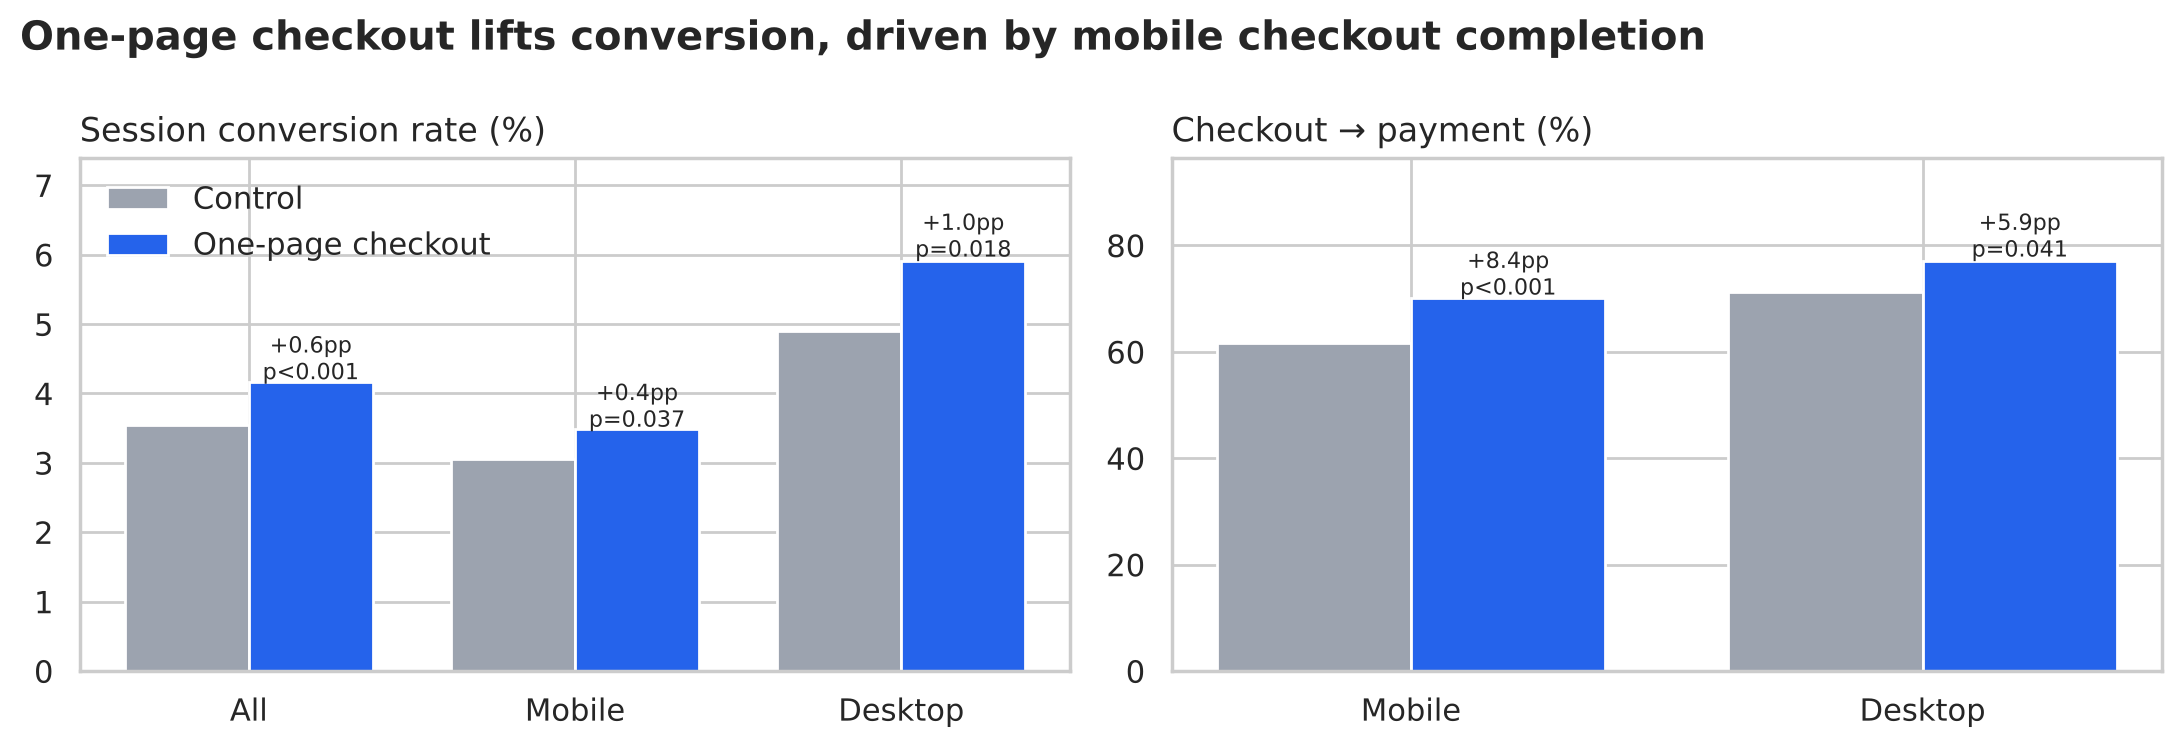

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (title, frame) in zip(axes, [("Session conversion rate (%)", pd.DataFrame({"All": primary, **{d: seg.loc[d] for d in ["mobile", "desktop"]}}).T),
                                     ("Checkout → payment (%)", chk)]):
    x = np.arange(len(frame)); w = 0.38
    ax.bar(x - w / 2, frame["control_rate_%"], w, color=GREY, label="Control")
    ax.bar(x + w / 2, frame["variant_rate_%"], w, color=BLUE, label="One-page checkout")
    for i, (_, r) in enumerate(frame.iterrows()):
        ax.text(i + w / 2, r["variant_rate_%"] * 1.01, f"+{r['abs_diff_pp']:.1f}pp\n" + ("p<0.001" if r['p_value'] < 0.001 else f"p={r['p_value']:.3f}"), ha="center", fontsize=8)
    ax.set_xticks(x, frame.index.str.title()); ax.set_title(title, loc="left"); ax.set_ylim(0, frame["variant_rate_%"].max() * 1.25)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("One-page checkout lifts conversion, driven by mobile checkout completion", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG / "11_ab_test_results.png", dpi=150, bbox_inches="tight"); plt.show()

## 7 · Regression adjustment: does the lift hold after controlling for mix?
Randomisation already balances the groups, but a logistic regression that controls for device, visitor type, channel and page
speed is a robustness check (and usually tightens the confidence interval).

In [10]:
t["slow"] = (t.page_load_ms > 3000).astype(int)
m = smf.logit("purchase ~ variant + C(device) + is_returning + C(channel) + slow", data=t).fit(disp=False)
or_ = np.exp(m.params["variant"]); ci = np.exp(m.conf_int().loc["variant"])
print(f"Variant odds ratio: {or_:.3f}  (95% CI {ci[0]:.3f}–{ci[1]:.3f}),  p = {m.pvalues['variant']:.4f}")
m.summary2().tables[1].loc[["variant", "is_returning", "slow"]].round(4)

Variant odds ratio: 1.191  (95% CI 1.079–1.315),  p = 0.0005


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
variant,0.1746,0.0505,3.4567,0.0005,0.0756,0.2736
is_returning,0.4824,0.0639,7.5554,0.0000,0.3573,0.6076
slow,-0.6299,0.0731,-8.6113,0.0000,-0.7732,-0.4865


The adjusted effect is about the same as the raw one, so **the result isn't driven by group mix**.
Being a returning visitor and having a fast page also matter a lot, which confirms Notebook 03.

## 8 · Was the test big enough?

In [11]:
p0 = primary["control_rate_%"] / 100
n_arm = int(min(primary.control_n, primary.variant_n))
power = NormalIndPower()
mde = [(p1 - p0) * 100 for p1 in np.linspace(p0, p0 * 1.5, 2000)
       if power.power(proportion_effectsize(p1, p0), nobs1=n_arm, alpha=0.05) >= 0.8][0]
obs_power = power.power(proportion_effectsize(primary["variant_rate_%"] / 100, p0), nobs1=n_arm, alpha=0.05)
print(f"Sessions per arm: {n_arm:,}")
print(f"Minimum detectable effect at 80% power: +{mde:.2f} pp ({mde / (p0 * 100):.0%} relative)")
print(f"Power to detect the observed effect: {obs_power:.0%}")

Sessions per arm: 21,376
Minimum detectable effect at 80% power: +0.52 pp (15% relative)
Power to detect the observed effect: 91%


The observed lift is larger than the minimum detectable effect, so the test was adequately powered for the main result.
The desktop and tablet sub-groups were **not** sized for their own conclusions.

## 9 · Business impact of a full rollout

In [12]:
aov_all = o.net_value_inr.mean()
quarter_sessions = len(f)
d_cvr, lo_cvr, hi_cvr = primary.abs_diff_pp / 100, primary.ci95_low_pp / 100, primary.ci95_high_pp / 100
impact = pd.DataFrame({
    "scenario": ["Conservative (CI low)", "Expected (point estimate)", "Optimistic (CI high)"],
    "cvr_lift_pp": [100 * lo_cvr, 100 * d_cvr, 100 * hi_cvr],
})
impact["extra_orders_per_year"] = (impact.cvr_lift_pp / 100 * quarter_sessions * 4).round()
impact["extra_revenue_lakh_per_year"] = (impact.extra_orders_per_year * aov_all / 1e5).round(1)
impact.round(2)

,scenario,cvr_lift_pp,extra_orders_per_year,extra_revenue_lakh_per_year
0,Conservative (CI low),0.25,799.0,13.1
1,Expected (point estimate),0.61,1965.0,32.2
2,Optimistic (CI high),0.98,3131.0,51.3


Rolling out the one-page checkout to **100%** of traffic would add roughly the "expected" figure above per year, at today's traffic and AOV.
That's larger than the "close half the mobile gap" estimate from Notebook 03 (₹26 L) because the variant also helped desktop,
and because the lift is measured against all sessions.

### Caveats
* **Session-level randomisation:** a returning user could see both versions on different visits. User-level assignment would be cleaner.
* **Festive season:** the test ran during Sep–Oct. The lift may be smaller in a normal month; monitor after rollout.
* **Novelty effect:** check that the lift holds 4–6 weeks after rollout.

## ✅ Decision
**Ship the one-page checkout to 100% of mobile traffic now**: the overall lift is significant (+0.61 pp, +17%, p = 0.001),
the mechanism is right (mobile checkout → payment +8.4 pp, p < 0.001), the guardrails are flat and the result holds after
regression adjustment. **Roll out to desktop too** (no sign of harm), but treat the desktop
lift as unproven and keep a 5–10% holdout for 4 weeks to measure it properly.